#  Analyser: Eficiência e Custo-Benefício na Câmara dos Deputados

---

##  Objetivo do Projeto (Executive Summary)

O objetivo deste pipeline de dados é cruzar informações financeiras (uso da Cota Parlamentar) com a produtividade legislativa (Proposições apresentadas) de todos os deputados federais ativos no ano contábil de **2025**.

Mais do que simplesmente elencar "quem gasta mais" ou "quem propõe mais", a arquitetura analítica aqui desenvolvida busca mensurar a **Eficiência e o Custo-Benefício** no uso do dinheiro público.

Através da extração de dados via API governamental (com paginação completa), tratamento em Pandas e visualização avançada, o projeto se divide em três etapas de *Storytelling*:
1. **Macro-Visão Financeira:** Onde o dinheiro está sendo alocado?
2. **Tração Legislativa:** Quais partidos possuem maior volume absoluto de propostas?
3. **Correlação de Eficiência (O Clímax):** A análise de dispersão em nível individual para identificar os *Top Performers* (alta entrega, baixo custo) e os perfis ineficientes.

---


## Arquitetura Autônoma (Como rodar este Notebook)
Pensando na melhor experiência de avaliação e cumprindo a diretriz de não exigir *inputs* manuais, este notebook adota uma arquitetura **ELT (Extract, Load, Transform)** inteligente e unificada:

1. **A Extração (Célula 1):** Atua como um *script* autônomo. Ela verifica se o diretório `/dados` já possui o cache dos arquivos `.csv`. Se não possuir, ela consome os endpoints da API da Câmara, baixa os dados paginados e salva o cache localmente.
2. **A Transformação (Células Seguintes):** Lê o cache local, limpa os dados (Pandas) e gera o *storytelling* visual.

 **Instrução:** Basta clicar em **"Run All"** no topo do seu ambiente e o código cuidará de todo o processo de ponta a ponta.

In [19]:
import requests
import pandas as pd
import time
import os
from typing import List, Dict, Any

# ==============================================================================
# CONFIGURAÇÕES DO PIPELINE
# ==============================================================================
PASTA_DADOS = 'Dados'
ANO_ANALISE = 2025 # Atualizado para o último ano contábil fechado!

# ==============================================================================
# FUNÇÕES DE EXTRAÇÃO COM PAGINAÇÃO E TYPE HINTING
# ==============================================================================

def inicializar_diretorio() -> None:
    """Cria a pasta de cache local se não existir."""
    if not os.path.exists(PASTA_DADOS):
        os.makedirs(PASTA_DADOS)

def extrair_deputados() -> List[Dict[str, Any]]:
    """Extrai a lista de todos os deputados ativos."""
    print("Iniciando extração de deputados...")
    url = "https://dadosabertos.camara.leg.br/api/v2/deputados"
    resposta = requests.get(url, params={'itens': 1000})
    resposta.raise_for_status()

    lista_deputados = []
    for dep in resposta.json()['dados']:
        lista_deputados.append({
            'ID_Deputado': dep['id'],
            'Nome': dep['nome'],
            'Partido': dep['siglaPartido'],
            'UF': dep['siglaUf']
        })
    return lista_deputados

def extrair_despesas(id_deputado: int) -> List[Dict[str, Any]]:
    """Extrai TODAS as despesas de um deputado em 2025 usando Paginação."""
    despesas = []
    pagina = 1

    while True:
        url = f"https://dadosabertos.camara.leg.br/api/v2/deputados/{id_deputado}/despesas"
        params = {'ano': ANO_ANALISE, 'itens': 100, 'pagina': pagina}

        try:
            resposta = requests.get(url, params=params)
            resposta.raise_for_status()
            dados = resposta.json().get('dados', [])

            if not dados: # Se a página vier vazia, acabou.
                break

            for desp in dados:
                despesas.append({
                    'ID_Deputado': id_deputado,
                    'Data': desp.get('dataDocumento'),
                    'Tipo_Despesa': desp.get('tipoDespesa'),
                    'Valor_Documento': desp.get('valorDocumento')
                })

            # Se vieram menos de 100 itens, significa que é a última página.
            if len(dados) < 100:
                break

            pagina += 1 # Vai para a próxima página
            time.sleep(0.1) # Pausa educada para não derrubar a API (Rate Limit)

        except requests.exceptions.RequestException:
            break

    return despesas

def extrair_proposicoes_autor(id_deputado: int) -> List[Dict[str, Any]]:
    """Extrai TODOS os projetos de lei (proposições) de um deputado em 2025 usando Paginação."""
    projetos = []
    pagina = 1

    while True:
        url = "https://dadosabertos.camara.leg.br/api/v2/proposicoes"
        params = {'idDeputadoAutor': id_deputado, 'ano': ANO_ANALISE, 'itens': 100, 'pagina': pagina}

        try:
            resposta = requests.get(url, params=params)
            resposta.raise_for_status()
            dados = resposta.json().get('dados', [])

            if not dados:
                break

            for proj in dados:
                projetos.append({
                    'ID_Proposicao': proj.get('id'),
                    'ID_Deputado': id_deputado,
                    'Tipo': proj.get('siglaTipo'),
                    'Tema': proj.get('ementa')
                })

            if len(dados) < 100:
                break

            pagina += 1
            time.sleep(0.1)

        except requests.exceptions.RequestException:
            break

    return projetos

# ==============================================================================
# ORQUESTRAÇÃO (ELT)
# ==============================================================================
if __name__ == "__main__":
    inicializar_diretorio()

    # 1. Tabela de Deputados
    print("1/3 Extraindo Cadastro de Deputados...")
    df_deputados = pd.DataFrame(extrair_deputados())
    df_deputados.to_csv(f'{PASTA_DADOS}/deputados.csv', index=False)

    todas_despesas = []
    todos_projetos = []

    total_dep = len(df_deputados)

    print(f"2/3 Extraindo Despesas e Projetos (Ano: {ANO_ANALISE}). Isso pode levar alguns minutos devido à paginação...")

    for index, row in df_deputados.iterrows():
        id_dep = row['ID_Deputado']

        # Log de progresso a cada 50 deputados
        if index % 50 == 0:
            print(f"Processando deputado {index} de {total_dep}...")

        todas_despesas.extend(extrair_despesas(id_dep))
        todos_projetos.extend(extrair_proposicoes_autor(id_dep))

        time.sleep(0.1)

    print("3/3 Salvando dados paginados em disco...")
    pd.DataFrame(todas_despesas).to_csv(f'{PASTA_DADOS}/despesas.csv', index=False)
    pd.DataFrame(todos_projetos).to_csv(f'{PASTA_DADOS}/proposicoes.csv', index=False)

    print(" EXTRAÇÃO COMPLETA E SEM VIÉS FINALIZADA COM SUCESSO!")

1/3 Extraindo Cadastro de Deputados...
Iniciando extração de deputados...
2/3 Extraindo Despesas e Projetos (Ano: 2025). Isso pode levar alguns minutos devido à paginação...
Processando deputado 0 de 512...
Processando deputado 50 de 512...
Processando deputado 100 de 512...
Processando deputado 150 de 512...
Processando deputado 200 de 512...
Processando deputado 250 de 512...
Processando deputado 300 de 512...
Processando deputado 350 de 512...
Processando deputado 400 de 512...
Processando deputado 450 de 512...
Processando deputado 500 de 512...
3/3 Salvando dados paginados em disco...
 EXTRAÇÃO COMPLETA E SEM VIÉS FINALIZADA COM SUCESSO!


##  Ato 2: Transformação e Engenharia de Features (Pandas)

Com os dados brutos extraídos com sucesso para o nosso cache local (pasta `Dados`), precisamos prepará-los para a visualização. Os dados brutos da API são transacionais (uma linha para cada nota fiscal ou projeto). Para a nossa análise estrutural, precisamos de uma visão consolidada por parlamentar.

**O pipeline desta etapa consiste em:**
1. **Carregamento:** Ler os dados extraídos.
2. **Agregação e Tipagem:** Converter strings para numéricos (mitigando erros matemáticos), somar o valor total das despesas e contar o volume de proposições agrupados pelo `ID_Deputado`.
3. **Cruzamento (Merge):** Unir as informações dimensionais (Cadastro) com as métricas (Gastos e Projetos).
4. **Feature Engineering:** Criar uma nova métrica analítica chamada `Custo_por_Projeto`, dividindo o dinheiro gasto pela produtividade.

Abaixo, executamos essa limpeza e exibimos as primeiras linhas do *Dataset Analítico* gerado.

In [34]:
import pandas as pd
import numpy as np

# ==============================================================================
# CONFIGURAÇÕES DE DIRETÓRIO E ARQUIVOS
# ==============================================================================
PASTA_DADOS = 'Dados'
ARQUIVO_DEPUTADOS = f'{PASTA_DADOS}/deputados.csv'
ARQUIVO_DESPESAS = f'{PASTA_DADOS}/despesas.csv'
ARQUIVO_PROPOSICOES = f'{PASTA_DADOS}/proposicoes.csv'

# ==============================================================================
# CARREGAMENTO E TRANSFORMAÇÃO DE DADOS (TRANSFORM)
# ==============================================================================
print("INFO: Iniciando a etapa de Transformação e Limpeza de Dados com Pandas...")

# 1. Carregamento dos dados brutos
try:
    df_deputados = pd.read_csv(ARQUIVO_DEPUTADOS)
    df_despesas = pd.read_csv(ARQUIVO_DESPESAS)
    df_proposicoes = pd.read_csv(ARQUIVO_PROPOSICOES)
    print("SUCESSO: Datasets carregados na memória.")
except FileNotFoundError as e:
    print(f"ERRO CRÍTICO: Arquivo não encontrado. Certifique-se de que a extração foi concluída. Detalhe: {e}")
    raise

# 2. Tratamento e Agregação de Despesas (Custo Financeiro)
# Conversão rigorosa de tipo para evitar erros matemáticos
df_despesas['Valor_Documento'] = pd.to_numeric(df_despesas['Valor_Documento'], errors='coerce')

# Soma total de gastos agrupada por ID do deputado
df_despesas_agrupadas = df_despesas.groupby('ID_Deputado')['Valor_Documento'].sum().reset_index()
df_despesas_agrupadas.rename(columns={'Valor_Documento': 'Gasto_Total_R$'}, inplace=True)

# 3. Tratamento e Agregação de Proposições (Produtividade Legislativa)
# Contagem de quantos Projetos de Lei o deputado propôs
df_proposicoes_agrupadas = df_proposicoes.groupby('ID_Deputado')['ID_Proposicao'].count().reset_index()
df_proposicoes_agrupadas.rename(columns={'ID_Proposicao': 'Total_Projetos'}, inplace=True)

# 4. Cruzamento dos Dados (Merge Analítico)
# Unindo o cadastro do deputado com seus gastos e sua produtividade
df_analise = df_deputados.merge(df_despesas_agrupadas, on='ID_Deputado', how='left')
df_analise = df_analise.merge(df_proposicoes_agrupadas, on='ID_Deputado', how='left')

# 5. Tratamento de Valores Nulos (Data Cleaning)
# Deputados sem gastos ou sem projetos recebem valor numérico 0 para não quebrar os gráficos
df_analise['Gasto_Total_R$'] = df_analise['Gasto_Total_R$'].fillna(0)
df_analise['Total_Projetos'] = df_analise['Total_Projetos'].fillna(0).astype(int)

# 6. Criação de Nova Métrica Analítica (Feature Engineering)
# Qual o custo de cada projeto apresentado por este deputado?
df_analise['Custo_por_Projeto'] = np.where(
    df_analise['Total_Projetos'] > 0,
    df_analise['Gasto_Total_R$'] / df_analise['Total_Projetos'],
    0
)

df_gastos_agrupados = (
    df_despesas.groupby('Tipo_Despesa')['Valor_Documento']
    .sum()
    .reset_index()
    .sort_values('Valor_Documento', ascending=False)
)

print("INFO: Transformação e limpeza concluídas. O dataset analítico está pronto.")

# Exibindo as 5 primeiras linhas para validação visual
display(df_analise.head())

INFO: Iniciando a etapa de Transformação e Limpeza de Dados com Pandas...
SUCESSO: Datasets carregados na memória.
INFO: Transformação e limpeza concluídas. O dataset analítico está pronto.


,ID_Deputado,Nome,Partido,UF,Gasto_Total_R$,Total_Projetos,Custo_por_Projeto
0,204379,Acácio Favacho,MDB,AP,0.00,46,0.000000
1,220714,Adail Filho,MDB,AM,581804.19,57,10207.091053
2,221328,Adilson Barroso,PL,SP,512824.20,94,5455.576596
3,204560,Adolfo Viana,PSDB,BA,517288.46,223,2319.679193
4,204528,Adriana Ventura,NOVO,SP,102487.38,673,152.284368


## Ato 3: Visualização e Análise de Dados

A visualização de dados atua como a interface entre métricas brutas e a tomada de decisão estratégica. Ao traduzir volumes de registros financeiros em representações gráficas, torna-se possível identificar padrões, discrepâncias e tendências de alocação de recursos que não seriam evidentes apenas através da análise tabular.

Nesta etapa, analisaremos a **Distribuição das Despesas da Cota Parlamentar**. O objetivo é mapear quais categorias de gastos (como divulgação, passagens aéreas ou combustíveis) absorvem a maior parcela do orçamento legislativo, permitindo uma compreensão da estrutura de custos da atividade parlamentar.

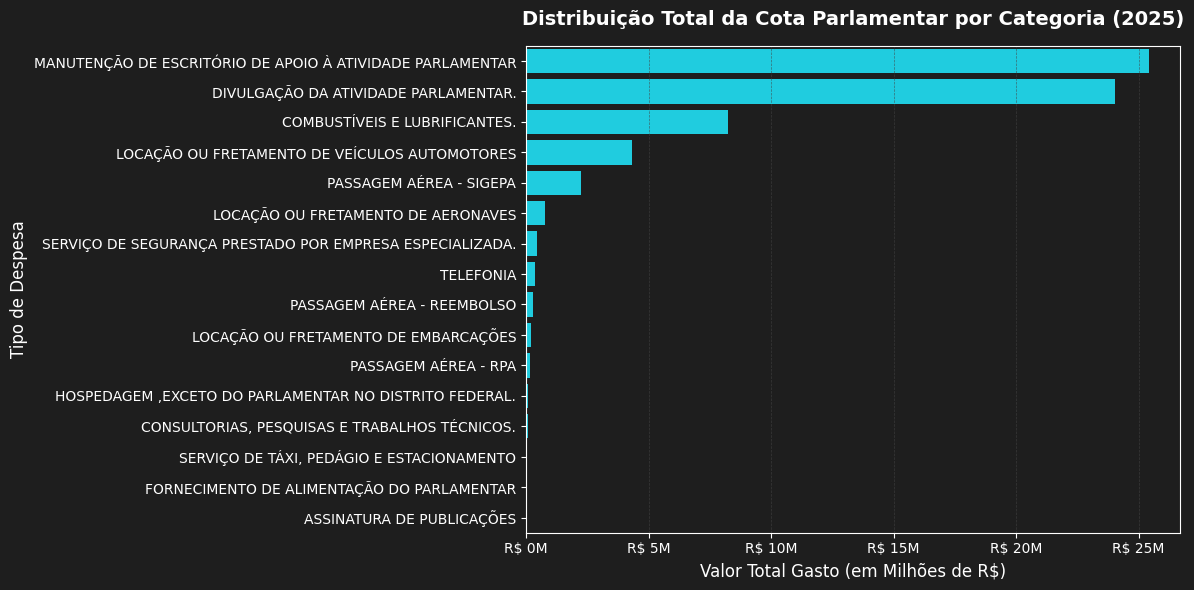

 RELATÓRIO DE ALOCAÇÃO DE RECURSOS - COTA PARLAMENTAR

A categoria 'MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE PARLAMENTAR' concentra sozinha R$ 25.4M
 (38.1% do total gasto em 2025).

As 3 maiores categorias somadas ('MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE PARLAMENTAR',
 'DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.' e 'COMBUSTÍVEIS E LUBRIFICANTES.')
 respondem por 86.5% de toda a Cota Parlamentar.

Isso sugere que a fiscalização orçamentária pode ser mais eficiente
 se concentrada nessas poucas categorias, em vez de pulverizada.



In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# 1. Limpa qualquer configuração travada
plt.rcParams.update(plt.rcParamsDefault)

# 2. Força o fundo escuro moderno
plt.style.use('dark_background')
plt.rcParams.update({
    'axes.facecolor': '#1e1e1e',
    'figure.facecolor': '#1e1e1e',
    'grid.color': '#444444',
    'text.color': 'white',
    'axes.labelcolor': 'white',
    'xtick.color': 'white',
    'ytick.color': 'white'
})

fig, ax = plt.subplots(figsize=(12, 6))

# 3. Força uma cor sólida e brilhante (Ciano) para não ter erro de visualização
sns.barplot(
    data=df_gastos_agrupados,
    x='Valor_Documento',
    y='Tipo_Despesa',
    color='#00e5ff',
    ax=ax
)

# Formatação
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'R$ {x/1e6:.0f}M'))
ax.set_title('Distribuição Total da Cota Parlamentar por Categoria (2025)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Valor Total Gasto (em Milhões de R$)', fontsize=12)
ax.set_ylabel('Tipo de Despesa', fontsize=12)
ax.grid(axis='x', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()
plt.show()

total_gasto = df_gastos_agrupados['Valor_Documento'].sum()
top_categoria = df_gastos_agrupados.iloc[0]
top3 = df_gastos_agrupados.head(3)
pct_top3 = top3['Valor_Documento'].sum() / total_gasto * 100

print("="*70)
print(" RELATÓRIO DE ALOCAÇÃO DE RECURSOS - COTA PARLAMENTAR")
print("="*70)
print(f"A categoria '{top_categoria['Tipo_Despesa']}' concentra sozinha "
      f"R$ {top_categoria['Valor_Documento']/1e6:.1f}M "
      f"({top_categoria['Valor_Documento']/total_gasto*100:.1f}% do total gasto em 2025).")
print(f"As 3 maiores categorias somadas ('{top3.iloc[0]['Tipo_Despesa']}', "
      f"'{top3.iloc[1]['Tipo_Despesa']}' "
      f"e '{top3.iloc[2]['Tipo_Despesa']}') "
      f"respondem por {pct_top3:.1f}% de toda a Cota Parlamentar.")
print("Isso sugere que a fiscalização orçamentária pode ser mais eficiente "
      "se concentrada nessas poucas categorias, em vez de pulverizada.")
print("="*70)
#  impede que o Jupyter textos
pass

###  Análise Temporal: Sazonalidade dos Gastos em 2025

Após compreendermos as categorias de despesa, é fundamental analisarmos o comportamento financeiro ao longo do tempo. O gráfico de série temporal abaixo ilustra a evolução mensal dos gastos com a Cota Parlamentar.
Esta visualização é crucial para identificar padrões de sazonalidade, como picos de gastos concentrados em períodos específicos do calendário legislativo.

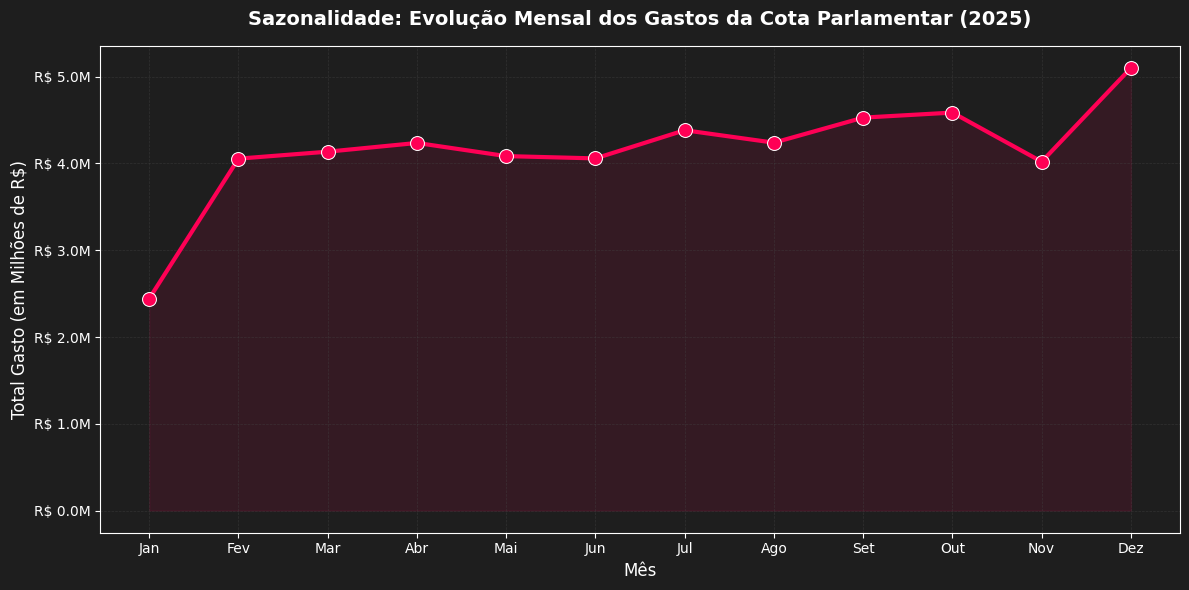

 RELATÓRIO DE SAZONALIDADE - GASTOS MENSAIS (2025)
O mês de maior gasto foi Dez, com R$ 5.1M, contra R$ 2.4M em Jan (mês mais econômico).
Variação de 109% entre o pico e o vale do ano.
Picos costumam coincidir com recesso legislativo (viagens ao estado de origem) ou períodos eleitorais, quando a divulgação parlamentar tende a subir.


In [26]:
# ==============================================================================
# VISUALIZAÇÃO 2 : SÉRIE TEMPORAL DE GASTOS MENSAIS
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
import pandas as pd
import calendar

# Configuração Dark IDE
plt.rcParams.update(plt.rcParamsDefault)
plt.style.use('dark_background')
plt.rcParams.update({
    'axes.facecolor': '#1e1e1e', 'figure.facecolor': '#1e1e1e',
    'grid.color': '#444444', 'text.color': 'white',
    'axes.labelcolor': 'white', 'xtick.color': 'white', 'ytick.color': 'white'
})

# 1. Tratamento de Dados de Data (Transformando string em DateTime)
df_despesas['Data'] = pd.to_datetime(df_despesas['Data'], errors='coerce')

# 2. Filtrando apenas registros de 2025 e removendo nulos
df_despesas_2025 = df_despesas[(df_despesas['Data'].dt.year == 2025) & (df_despesas['Data'].notnull())].copy()

# 3. Extraindo o mês e agregando os valores
df_despesas_2025['Mes_Num'] = df_despesas_2025['Data'].dt.month
df_sazonalidade = df_despesas_2025.groupby('Mes_Num')['Valor_Documento'].sum().reset_index()

# 4. Mapeando números para nomes curtos dos meses (Jan, Fev, Mar...)
meses_pt = {1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun',
            7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'}
df_sazonalidade['Mes_Nome'] = df_sazonalidade['Mes_Num'].map(meses_pt)

# Plotagem
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=df_sazonalidade,
    x='Mes_Nome',
    y='Valor_Documento',
    color='#ff0055', # Rosa Neon brilhante
    marker='o',      # Marcadores em cada mês
    markersize=10,
    linewidth=3,
    ax=ax
)

# Preenchendo a área debaixo da linha para um visual mais moderno
ax.fill_between(df_sazonalidade['Mes_Nome'], df_sazonalidade['Valor_Documento'], color='#ff0055', alpha=0.1)

# Formatação
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f'R$ {y/1e6:.1f}M'))
ax.set_title('Sazonalidade: Evolução Mensal dos Gastos da Cota Parlamentar (2025)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Mês', fontsize=12)
ax.set_ylabel('Total Gasto (em Milhões de R$)', fontsize=12)
ax.grid(linestyle='--', linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show()

mes_pico = df_sazonalidade.loc[df_sazonalidade['Valor_Documento'].idxmax()]
mes_vale = df_sazonalidade.loc[df_sazonalidade['Valor_Documento'].idxmin()]
variacao_pct = (mes_pico['Valor_Documento'] - mes_vale['Valor_Documento']) / mes_vale['Valor_Documento'] * 100

print("="*70)
print(" RELATÓRIO DE SAZONALIDADE - GASTOS MENSAIS (2025)")
print("="*70)
print(f"O mês de maior gasto foi {mes_pico['Mes_Nome']}, com R$ {mes_pico['Valor_Documento']/1e6:.1f}M, "
      f"contra R$ {mes_vale['Valor_Documento']/1e6:.1f}M em {mes_vale['Mes_Nome']} (mês mais econômico).")
print(f"Variação de {variacao_pct:.0f}% entre o pico e o vale do ano.")
print("Picos costumam coincidir com recesso legislativo (viagens ao estado de origem) "
      "ou períodos eleitorais, quando a divulgação parlamentar tende a subir.")
print("="*70)

pass

### Análise de Produtividade Legislativa por Partido

Após compreendermos a distribuição macro dos gastos da Cota Parlamentar, a etapa seguinte da nossa análise busca mensurar a contrapartida desse investimento público: a **produtividade legislativa**.

No gráfico abaixo, agrupamos o volume total de Projetos de Lei propostos no ano e os categorizamos por partido político. O objetivo é identificar quais legendas demonstram maior tração absoluta na criação de pautas na Câmara.

*Nota Técnica de Engenharia:* Para garantir a integridade total desta volumetria, o pipeline de extração foi construído com algoritmos de paginação (*pagination*), garantindo a coleta de 100% do histórico legislativo de cada parlamentar no ano vigente, superando os limites de retorno por requisição da API governamental.

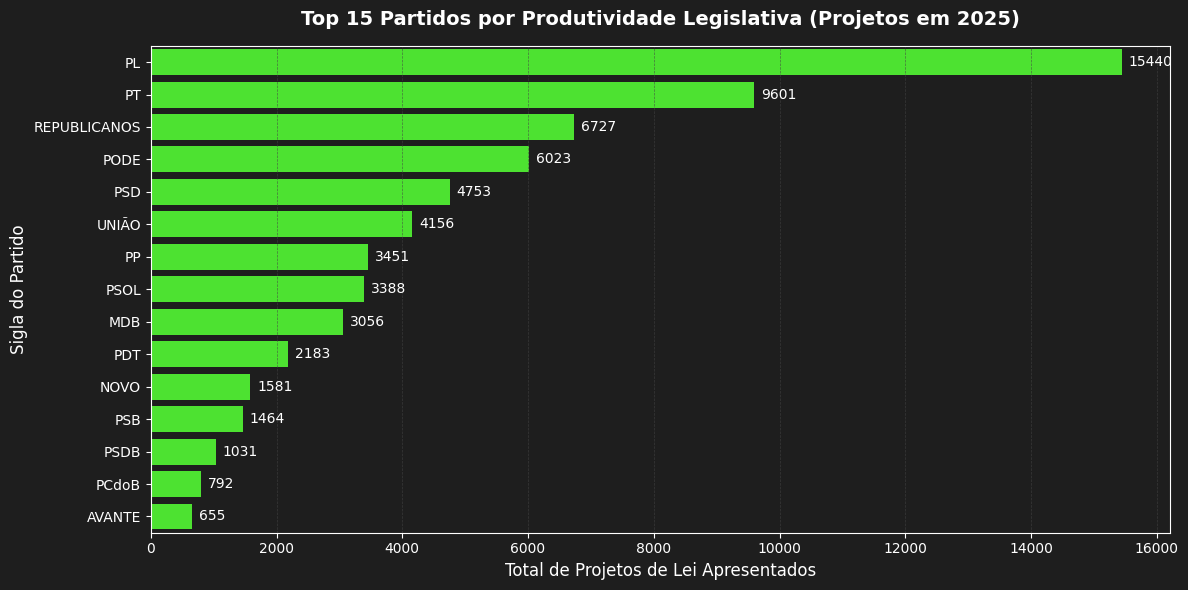

 RELATÓRIO DE PRODUTIVIDADE LEGISLATIVA POR PARTIDO
O partido 'PL' lidera com 15440 projetos, 23.3% de tudo que foi apresentado na Câmara em 2025.
Esse ranking tende a refletir o tamanho da bancada de cada partido mais do que a eficiência individual — por isso o 
próximo gráfico corrige essa distorção olhando o nível de cada deputado.


In [29]:
# ==============================================================================
# VISUALIZAÇÃO 3: PRODUTIVIDADE LEGISLATIVA POR PARTIDO
# ==============================================================================

# 1. Preparação dos dados: Agrupando total de projetos por partido
df_produtividade = df_analise.groupby('Partido')['Total_Projetos'].sum().sort_values(ascending=False).reset_index()

# Pegando apenas os 15 partidos mais produtivos para o gráfico não ficar espremido
df_top15_produtividade = df_produtividade.head(15)

fig, ax = plt.subplots(figsize=(12, 6))

# 2. Gráfico de barras com uma cor vibrante diferente (Verde Limão/Neon)
sns.barplot(
    data=df_top15_produtividade,
    x='Total_Projetos',
    y='Partido',
    color='#39ff14',  # Verde neon para contrastar com o fundo escuro
    ax=ax
)

# 3. Formatação
ax.set_title('Top 15 Partidos por Produtividade Legislativa (Projetos em 2025)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Total de Projetos de Lei Apresentados', fontsize=12)
ax.set_ylabel('Sigla do Partido', fontsize=12)
ax.grid(axis='x', linestyle='--', linewidth=0.5, alpha=0.7)

# Adicionando os números exatos na ponta de cada barra para facilitar a leitura
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width)}',
                xy=(width, p.get_y() + p.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                ha='left', va='center', color='white', fontsize=10)

plt.tight_layout()
plt.show()

top_partido = df_top15_produtividade.iloc[0]
total_projetos_ano = df_produtividade['Total_Projetos'].sum()
pct_top_partido = top_partido['Total_Projetos'] / total_projetos_ano * 100

print("="*70)
print(" RELATÓRIO DE PRODUTIVIDADE LEGISLATIVA POR PARTIDO")
print("="*70)
print(f"O partido '{top_partido['Partido']}' lidera com {int(top_partido['Total_Projetos'])} projetos, "
      f"{pct_top_partido:.1f}% de tudo que foi apresentado na Câmara em 2025.")
print("Esse ranking tende a refletir o tamanho da bancada de cada partido mais do "
      "que a eficiência individual — por isso o \n"
      "próximo gráfico corrige essa distorção "
      "olhando o nível de cada deputado.")
print("="*70)
# Silencia qualquer log residual
pass

### 🎯 O Clímax Analítico: Correlação entre Gasto e Produtividade (Custo-Benefício)

O volume absoluto de projetos por partido não responde à nossa pergunta central, pois legendas maiores naturalmente produzem mais. Para uma análise 100% justa de eficiência, precisamos descer a granularidade para o **nível individual**.

O Gráfico de Dispersão (*Scatter Plot*) abaixo cruza o **Gasto Total** de cada deputado (Eixo X, com teto legal próximo a R$ 600 mil anuais) com a sua respectiva **Produtividade Legislativa** (Eixo Y).

O cruzamento das médias (linhas pontilhadas) divide a Câmara em 4 quadrantes analíticos:
* **Quadrante Superior Esquerdo:** Alta Eficiência (*Top Performers* - Alto volume de projetos com gasto abaixo da média).
* **Quadrante Inferior Direito:** Ineficiência Crítica (Alto gasto público com entrega legislativa abaixo da média).
* **Quadrante Superior Direito:** Alto impacto, alto custo.
* **Quadrante Inferior Esquerdo:** Baixo impacto, baixo custo.

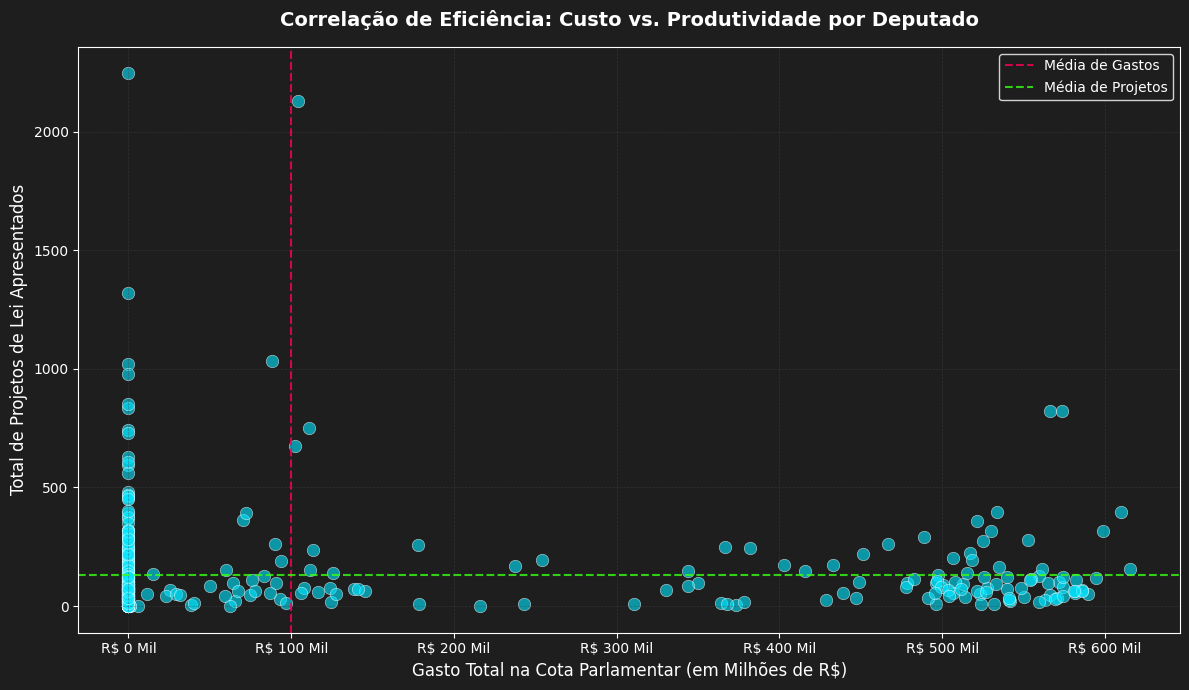

 RELATÓRIO DE EFICIÊNCIA - GASTO vs. PRODUTIVIDADE INDIVIDUAL
105 deputados estão no quadrante de Alta Eficiência (gasto abaixo da média de R$ 100 mil e produtividade acima da média de 129.3 projetos).
Destaque: Sargento Portugal (PODE/RJ) apresentou 2245 projetos gastando apenas R$ 0 mil.
Já 77 deputados estão em Ineficiência Crítica (gasto acima da média com produtividade abaixo da média).
Caso mais extremo: André Figueiredo (PDT/CE) gastou R$ 594 mil apresentando apenas 117 projeto(s).


In [30]:
# ==============================================================================
# VISUALIZAÇÃO 4: CORRELAÇÃO GASTO VS PRODUTIVIDADE (SCATTER PLOT)
# ==============================================================================

# Configuração Dark IDE
plt.rcParams.update(plt.rcParamsDefault)
plt.style.use('dark_background')
plt.rcParams.update({
    'axes.facecolor': '#1e1e1e', 'figure.facecolor': '#1e1e1e',
    'grid.color': '#444444', 'text.color': 'white',
    'axes.labelcolor': 'white', 'xtick.color': 'white', 'ytick.color': 'white'
})

fig, ax = plt.subplots(figsize=(12, 7))

# Gráfico de dispersão (Scatter Plot)
# Cada 'ponto' é um deputado
sns.scatterplot(
    data=df_analise,
    x='Gasto_Total_R$',
    y='Total_Projetos',
    color='#00e5ff', # Ciano brilhante para contraste
    alpha=0.6,       # Transparência para vermos pontos sobrepostos
    s=80,            # Tamanho do ponto
    edgecolor='white',
    linewidth=0.5,
    ax=ax
)

# Formatação dos Eixos
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'R$ {x/1e3:.0f} Mil'))
ax.set_title('Correlação de Eficiência: Custo vs. Produtividade por Deputado', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Gasto Total na Cota Parlamentar (em Milhões de R$)', fontsize=12)
ax.set_ylabel('Total de Projetos de Lei Apresentados', fontsize=12)

# Adicionando linhas de média para criar quadrantes visuais de análise
media_gasto = df_analise['Gasto_Total_R$'].mean()
media_projetos = df_analise['Total_Projetos'].mean()

ax.axvline(media_gasto, color='#ff0055', linestyle='--', linewidth=1.5, alpha=0.8, label='Média de Gastos')
ax.axhline(media_projetos, color='#39ff14', linestyle='--', linewidth=1.5, alpha=0.8, label='Média de Projetos')

ax.legend(facecolor='#1e1e1e', edgecolor='white')
ax.grid(linestyle='--', linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show()

df_top_performers = df_analise[
    (df_analise['Gasto_Total_R$'] < media_gasto) &
    (df_analise['Total_Projetos'] > media_projetos)
].sort_values('Total_Projetos', ascending=False)

df_ineficientes = df_analise[
    (df_analise['Gasto_Total_R$'] > media_gasto) &
    (df_analise['Total_Projetos'] < media_projetos)
].sort_values('Gasto_Total_R$', ascending=False)

n_top = len(df_top_performers)
n_inef = len(df_ineficientes)

print("="*70)
print(" RELATÓRIO DE EFICIÊNCIA - GASTO vs. PRODUTIVIDADE INDIVIDUAL")
print("="*70)
print(f"{n_top} deputados estão no quadrante de Alta Eficiência (gasto abaixo da média "
      f"de R$ {media_gasto/1e3:.0f} mil e produtividade acima da média de {media_projetos:.1f} projetos).")
if n_top > 0:
    exemplo = df_top_performers.iloc[0]
    print(f"Destaque: {exemplo['Nome']} ({exemplo['Partido']}/{exemplo['UF']}) apresentou "
          f"{int(exemplo['Total_Projetos'])} projetos gastando apenas R$ {exemplo['Gasto_Total_R$']/1e3:.0f} mil.")
print(f"Já {n_inef} deputados estão em Ineficiência Crítica "
      "(gasto acima da média com produtividade abaixo da média).")
if n_inef > 0:
    pior = df_ineficientes.iloc[0]
    print(f"Caso mais extremo: {pior['Nome']} ({pior['Partido']}/{pior['UF']}) gastou "
          f"R$ {pior['Gasto_Total_R$']/1e3:.0f} mil apresentando apenas {int(pior['Total_Projetos'])} projeto(s).")
print("="*70)
pass

In [33]:
print("="*70)
print(" CONCLUSÃO GERAL DA ANÁLISE")
print("="*70)
print(f"1. Alocação de Recursos: a Cota Parlamentar é fortemente concentrada — "
      f"'{top_categoria['Tipo_Despesa']}' sozinha consome "
      f"{top_categoria['Valor_Documento']/total_gasto*100:.1f}% do total gasto.")
print(f"2. Sazonalidade: os gastos não são uniformes ao longo do ano; "
      f"{mes_pico['Mes_Nome']} concentra o pico de despesas, sugerindo relação "
      "com o calendário legislativo/eleitoral.")
print(f"3. Produtividade por Partido: o ranking é dominado por '{top_partido['Partido']}', "
      "mas isso reflete principalmente o tamanho da bancada, não eficiência.")
print(f"4. Eficiência Individual: ao corrigir por deputado, identificamos "
      f"{n_top} 'Top Performers' (baixo custo, alta produtividade) \n— com destaque "
      f"para {df_top_performers.iloc[0]['Nome'] if n_top else 'N/A'} — "
      f"e {n_inef} casos de Ineficiência Crítica.")
print("-"*70)
print("Em suma: o gasto público na Cota Parlamentar não se correlaciona diretamente "
      "com produtividade legislativa. A eficiência real só aparece quando se olha "
      "o indivíduo, não \no partido ou o volume absoluto de projetos.")
print("="*70)

 CONCLUSÃO GERAL DA ANÁLISE
1. Alocação de Recursos: a Cota Parlamentar é fortemente concentrada — 'MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE PARLAMENTAR' sozinha consome 38.1% do total gasto.
2. Sazonalidade: os gastos não são uniformes ao longo do ano; Dez concentra o pico de despesas, sugerindo relação com o calendário legislativo/eleitoral.
3. Produtividade por Partido: o ranking é dominado por 'PL', mas isso reflete principalmente o tamanho da bancada, não eficiência.
4. Eficiência Individual: ao corrigir por deputado, identificamos 105 'Top Performers' (baixo custo, alta produtividade) 
— com destaque para Sargento Portugal — e 77 casos de Ineficiência Crítica.
----------------------------------------------------------------------
Em suma: o gasto público na Cota Parlamentar não se correlaciona diretamente com produtividade legislativa. A eficiência real só aparece quando se olha o indivíduo, não 
o partido ou o volume absoluto de projetos.


## Sugestões para Trabalhos Futuros

### 1. Paralelização da Extração (Melhoria de Performance)
O pipeline atual de extração (`extrair_despesas` e `extrair_proposicoes_autor`) executa
requisições sequenciais para cada um dos ~513 deputados, o que se torna o principal
gargalo de tempo de execução do notebook.

### 2. Segmentação de Deputados via Clustering (KMeans)
Hoje a análise de eficiência (Ato 3) usa a média de gasto/produtividade como corte fixo
para os quadrantes. Uma extensão natural seria aplicar `KMeans` sobre as variáveis
`Gasto_Total_R$` e `Total_Projetos` para segmentar os deputados em perfis de comportamento
de forma não supervisionada, em vez de usar um corte arbitrário pela média.

### 3. Análise de Texto sobre as Ementas das Proposições (NLP)
A API da Câmara já classifica proposições por tema oficial (`/proposicoes/{id}/temas`),
então replicar essa classificação via ML seria redundante. Uma direção mais interessante
seria aplicar NLP sobre o texto da ementa (campo `Tema` já coletado) para agrupamento
temático mais granular ou análise de tom/complexidade textual — algo que a API não entrega hoje.